### Representation Learning: **Word2Vec**

Representation Learning Plan: 
* Load Cleaned Amazon Beauty Data
* Tokenize Individual Customer Reviews
* Train Word2Vec on Review Text
* Test similarities between beauty related words
* Visualize embeddings 
* Convert the reviews into vectors 
* Export and save the model and vectors to be used for clustering

### Load Cleaned Amazon Beauty Data

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
import re
from sklearn.manifold import TSNE
# Make sure Gensim is installed
from gensim.models import Word2Vec
# Make sure nltk is installed
from nltk.tokenize import word_tokenize

In [13]:
df = pd.read_pickle("beauty_clean.pkl")

print(df.shape)
df[["clean_text", "rating", "sentiment"]].head()

(693547, 10)


,clean_text,rating,sentiment
0,This spray is really nice. It smells really go...,5,Positive
1,"This product does what I need it to do, I just...",4,Positive
2,"Smells good, feels great!",5,Positive
3,Felt synthetic,1,Negative
4,Love it,5,Positive


There is a lot of data, so we will start with a sample of 50,000 reviews

In [3]:
df_sample = df.sample(n=50000, random_state=42).reset_index(drop=True)

print(df_sample["sentiment"].value_counts())

sentiment
Positive    35689
Negative    10275
Neutral      4036
Name: count, dtype: int64


### Tokenize the reviews
Turn raw paragraphs into a list of list of words using nltk

In [15]:
corp = []

# Make sure punctuation marks aren't kept in words, i.e. 'moisture.' vs. 'moisture'
for text in df_sample["clean_text"]:
    text = text.lower()
    text = re.sub(r"[^\w\s']", " ", text)
    tokens = word_tokenize(text, preserve_line=True)
    tokens = [word for word in tokens if any(c.isalpha() for c in word)]
    corp.append(tokens)

print("Number of tokenized reviews:", len(corp))

for sent in corp[:3]:
  print(sent)
  print("\n")

Number of tokenized reviews: 50000
['best', 'hand', 'cream', 'ever', 'i', 'love', 'it', 'light', 'fragrance', 'does', 'take', 'a', 'little', 'while', 'to', 'soak', 'in', 'completely', 'but', 'completely', 'worth', 'it', 'shipped', 'quickly', 'packaged', 'well', 'would', 'definitely', 'do', 'business', 'with', 'this', 'seller', 'again', 'a', 'a', 'a']


['makes', 'my', 'face', 'look', 'as', 'if', 'it', 'was', 'crafted', 'from', 'baby', 'bottoms', 'however', 'i', 'prefer', 'my', 'soufflé', 'edible']


['goes', 'on', 'fairly', 'smooth', 'without', 'being', 'too', 'smeary', 'can', 'use', 'as', 'close', 'to', 'lash', 'thin', 'line', 'or', 'wider', 'easily', 'love', 'the', 'color', 'no', 'irritation', 'either']




### Train Word2Vec Model

In [16]:
model = Word2Vec(
    sentences=corp,
    # Each word represented by 100 numbers
    vector_size=100,
    # Model learns from words within a window of 5 positions
    window=5,
    # Ignore words that appear less than 5 times
    min_count=5,
    # Use skipgram
    sg=1,
    workers=1,
    seed=42
)

print("Total words:", model.corpus_total_words)
print("Vocabulary size (Unique Words):", len(model.wv))

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Total words: 1671146
Vocabulary size (Unique Words): 8104


### Test similarities between product characteristics and complaint terms
1. Examine similar words
2. Test specific hypotheses

In [21]:
# Sample words
words = ["pigment", "irritation", "scent", "packaging"]

for word in words:
        print(f"Words similar to '{word}':")
        print(model.wv.most_similar(word, topn=3))

Words similar to 'pigment':
[('sheer', 0.7755832076072693), ('shimmery', 0.7575282454490662), ('dim', 0.7493346333503723)]
Words similar to 'irritation':
[('breakouts', 0.8396454453468323), ('reactions', 0.7900047302246094), ('redness', 0.7826656699180603)]
Words similar to 'scent':
[('fragrance', 0.904949426651001), ('smell', 0.876803994178772), ('overpowering', 0.8008619546890259)]
Words similar to 'packaging':
[('presentation', 0.7759998440742493), ('packing', 0.709038496017456), ('box', 0.6893745064735413)]


### Visualize embeddings using t-SNE

In [27]:
words = ["pigment", "shade", "blendable", "sheer", "irritation", "redness", "breakouts", 
         "sensitive", "dryness", "scent", "fragrance", "smell", "perfume", "overpowering"]

word_vectors = np.array([model.wv[word] for word in words])

tsne = TSNE(n_components=2, perplexity=5, random_state=42)
word_vectors_tsne = tsne.fit_transform(word_vectors)

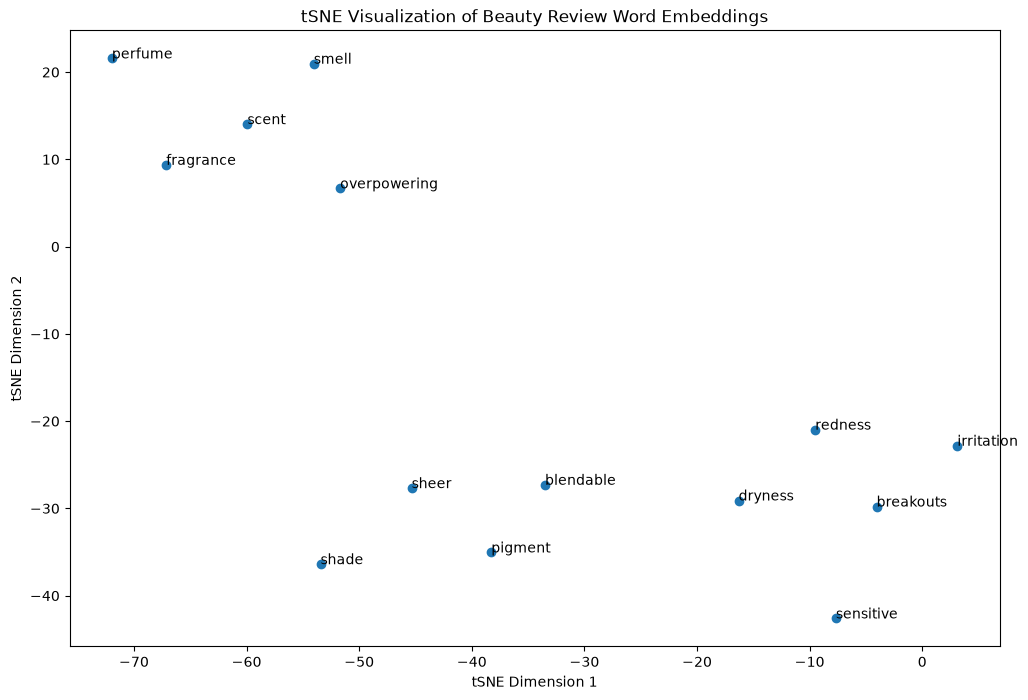

In [30]:
plt.figure(figsize=(12, 8))

# Plot each word's 2d coordinates
plt.scatter(word_vectors_tsne[:, 0], word_vectors_tsne[:, 1])

# Place a text label next to each point by looping through each word and it's index
for i, word in enumerate(words):
    plt.annotate(word, (word_vectors_tsne[i, 0], word_vectors_tsne[i, 1]))

plt.title("tSNE Visualization of Beauty Review Word Embeddings")
plt.xlabel("tSNE Dimension 1")
plt.ylabel("tSNE Dimension 2")
plt.show()

### Tokenize the Entire Dataset
- Previously we have been working with a smaller subsample of the data to make sure the model would learn meaningful relationships

- Now we are going to tokenize the entire dataset in order to do an analysis on the entire dataset

In [32]:
df_corp = []

# Make sure punctuation marks aren't kept in words, i.e. 'moisture.' vs. 'moisture'
for text in df["clean_text"]:
    text = text.lower()
    text = re.sub(r"[^\w\s']", " ", text)
    tokens = word_tokenize(text, preserve_line=True)
    tokens = [word for word in tokens if any(c.isalpha() for c in word)]
    df_corp.append(tokens)

print("Number of tokenized reviews:", len(df_corp))

for sent in df_corp[:3]:
  print(sent)
  print("\n")

Number of tokenized reviews: 693547
['this', 'spray', 'is', 'really', 'nice', 'it', 'smells', 'really', 'good', 'goes', 'on', 'really', 'fine', 'and', 'does', 'the', 'trick', 'i', 'will', 'say', 'it', 'feels', 'like', 'you', 'need', 'a', 'lot', 'of', 'it', 'though', 'to', 'get', 'the', 'texture', 'i', 'want', 'i', 'have', 'a', 'lot', 'of', 'hair', 'medium', 'thickness', 'i', 'am', 'comparing', 'to', 'other', 'brands', 'with', 'yucky', 'chemicals', 'so', 'i', "'m", 'gon', 'na', 'stick', 'with', 'this', 'try', 'it']


['this', 'product', 'does', 'what', 'i', 'need', 'it', 'to', 'do', 'i', 'just', 'wish', 'it', 'was', 'odorless', 'or', 'had', 'a', 'soft', 'coconut', 'smell', 'having', 'my', 'head', 'smell', 'like', 'an', 'orange', 'coffee', 'is', 'offputting', 'granted', 'i', 'did', 'know', 'the', 'smell', 'was', 'described', 'but', 'i', 'was', 'hoping', 'it', 'would', 'be', 'light']


['smells', 'good', 'feels', 'great']




### Train Word2Vec on the Entire Dataset

In [35]:
# Train Word2Vec on all reviews
full_model = Word2Vec(
    sentences=df_corp,
    # Each word represented by 100 numbers
    vector_size=100,
    # Model learns from words within a window of 5 positions
    window=5,
    # Ignore words that appear less than 5 times
    min_count=5,
    # Use skipgram
    sg=1,
    workers=1,
    seed=42
)

print("Total words:", full_model.corpus_total_words)
print("Vocabulary size (Unique Words):", len(full_model.wv))

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

Total words: 23165245
Vocabulary size (Unique Words): 26923


### Convert Reviews into Vectors
Currently Word2Vec gives us a 100-dimensional vector for each word

 We want one 100-dimensional vector for each *review*

 **How we'll do this**: 

1. Find the 100 dimensional vector for each word

2. Average those four vectors

3. Return one vector containing 100 numbers

In [37]:
def review_vector(tokens):
    vectors = [full_model.wv[word] for word in tokens if word in full_model.wv]

    if len(vectors) == 0:
        return np.zeros(100)

    return np.mean(vectors, axis=0)

### Create embeddings

Generate a matrix of review vectors with 693,547 rows and 100 columns

In [ ]:
# Initialize empty matrix
review_matrix = np.zeros((len(df_corp), 100), dtype=np.float32)

# Convert each review into a vector
for i, tokens in enumerate(df_corp):
    review_matrix[i] = review_vector(tokens)

print("Shape:", review_matrix.shape)

Shape: (693547, 100)


### Save the Vectors

In [45]:
# Save review vectors
np.save("beauty_review_vectors.npy", review_matrix)

full_model.save("beauty_word2vec.model")